<a href="https://colab.research.google.com/github/charlesdgburns/degist/blob/claude/gifted-einstein-qdzuf5/choices_and_climate_change_draft.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Draft v0.2.** Intro and neuroscience prose are Charles's (from the gist). Everything from *"A model of a decision"* onwards is a Claude-drafted bridge, written in Charles's voice to be picked apart and rewritten.

# Choices and climate change

This is a story about physics and maths being unified across scales - from the small changes in activity of neurons in brains to the large changes in ocean currents on earth. In some ways, this is also a personal story choosing to shift my focus from neuroscience to climate change. For you, I hope it's an interesting read about:

1. **How neurons give rise to decisions**, and
2. **When climate change will be irreversible**.

Here's **the gist**: both our brains and our climate rely on stable patterns in a system. Some stable states are *attractors*, points that the system is pulled towards without external input, like a marble running down a hill. The key point is that these stable states can take different shapes. In some cases, for example if there are exactly two attractors, this introduces a *tipping point*. It turns out, our neurons cross such a tipping point every time we choose left over right. We are also crossing such tipping points as we continue to emit carbon into our atmosphere. These tipping points keep apart the stable states, making it harder to switch from one to the other. For the brain this helps us separate actions like left and right, while for the climate this makes some changes very hard to reverse.

But how do we know the shape of the dynamical landscape? In some cases it could also be continuous, with a whole series of stable states that the system can move through, or have a single attractor that moves as the system changes. How do we identify the dynamical systems underlying our decisions or the climate?

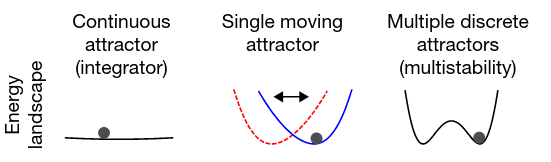


---


Let's **degist**: diving into the nitty gritty and answering the questions that naturally follow the big picture. We will take a closer look at two scientific papers which helped paint the picture for me:

1. **Discrete attractor dynamics underlies persistent activity in the frontal cortex** [(Inagaki et al., 2019)](https://drive.google.com/file/d/1zpUTz8pS4QDxQTPQhll0x70iFmCavl9V/view)
2. **Warning of a forthcoming collapse of the atlantic meridional overturning circulation** [(Ditlevsen & Ditlevsen, 2023)](https://www.nature.com/articles/s41467-023-39810-w).


# How neurons give rise to decisions

This story starts with studying decision-making from the perspective of computational neuroscience. We know that our nervous system acts as a result of thousands (millions of thousands) of neurons that connect and talk to each other through 'spikes', short bursts of electrical activity going from one neuron out to others. But how do these millions of neurons coordinate their activity to make complex movements, or even simple decisions?

Consider a really simple delayed response task: you hear a tone, wait 2 seconds, then choose left or right. When the tone is low-pitched, you'll get a reward on the left, and when the tone is high-pitched you'll get a reward on the right. When did you make your choice? If you know the task well, you might have made up your mind as soon as you recognised the pitch of the tone. But during those two seconds of waiting, your neurons must somehow store the information of the cue, keeping a memory, before you act and make a choice. How?

The answer lies in attractor dynamics, stable patterns of activity in the dynamical system of many neurons. In this case, a stable pattern of activity holds information as a memory which lets us make an informed choice. What exactly do I mean by pattern? Ironically, we can gain a lot of understanding of these thousands of neurons from modelling them as just a few 'populations'. One population is active whenever you choose to go left, the other population is active whenever you choose right. We can describe the activity of the two populations as the 'patterns' $[1,0]$ and $[0,1]$, but also $[0,0]$ if none are active and $[1,1]$ if both are.

This is what Hidehiko Inagaki saw when recording the neurons of mice doing this simple delayed response task - neurons consistently had one stable pattern of activity when mice chose to go left and another stable pattern when mice chose to go right. Each decision corresponds to a stable pattern of activity! The main question then is how do neurons go from one stable pattern to another - what is the dynamical landscape underlying decsions?


Consider three possible ladscapes: a single valley (single attractor), two valleys divided by a mountain (multiple attractors), or a flat plane (continous attractor).



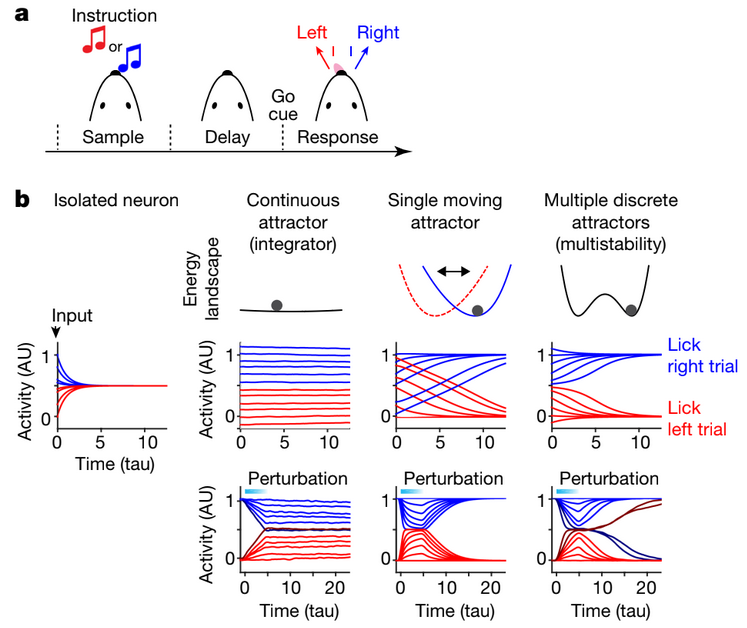

## A model of a decision

Let's build the smallest model I can think of that still makes a decision. Three populations: **Left** ($r_L$), **Right** ($r_R$) and a shared pool of **Inhibitory** neurons ($r_I$). Each population's activity relaxes towards a sigmoid of its input:

$$\tau_i \frac{dr_i}{dt} = -r_i + f\Big(\sum_j W_{ij} r_j + I_i\Big) + \text{noise}$$

Left and Right excite themselves, and both excite the inhibitory pool, which inhibits them both. Whoever gets ahead pushes the other one down. That is all it takes for two stable patterns, $[1,0]$ and $[0,1]$, to appear.

I've added one extra knob, $h$: a steady push towards *Right* (more input to Right, less to Left). You can think of it as contradictory evidence or a one-sided perturbation. It will turn out to be the bridge to the ocean.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
from scipy.optimize import fsolve, minimize
from scipy.integrate import solve_ivp, cumulative_trapezoid
warnings.filterwarnings('ignore', category=RuntimeWarning)  # harmless exp overflow in the sigmoid

C_L, C_R, C_FOLD = 'royalblue', 'crimson', 'darkorange'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})

# --- The Left / Right / Inhibitory model (same weights as the first draft) ---
W = np.array([[2.2, 0.2, -2.2],    # Left  <- [L, R, I]
              [0.2, 2.2, -2.2],    # Right <- [L, R, I]
              [1.1, 1.1, -0.5]])   # Inhib <- [L, R, I]
TAU    = np.array([0.2, 0.2, 0.05])   # seconds; inhibition is fast
THRESH = np.array([0.5, 0.5, 0.6])
GAIN   = 10.0
BASE   = np.array([0.4, 0.4, 0.1])    # baseline input

def f(x):
    return 1 / (1 + np.exp(-GAIN * (x - THRESH)))

def inputs(h=0.0, cue=0.0, opto=0.0):
    # h = push towards Right; cue = input to Left; opto = drive to the inhibitory pool
    return BASE + np.array([cue - h / 2, h / 2, opto])

def drift(r, h=0.0, cue=0.0, opto=0.0):
    # dr/dt without noise. r can be shape (3,) or (n_trials, 3)
    return (-r + f(r @ W.T + inputs(h, cue, opto))) / TAU

def jacobian(r, h=0.0):
    s = f(r @ W.T + inputs(h))
    return (-np.eye(3) + (GAIN * s * (1 - s))[:, None] * W) / TAU[:, None]

def simulate(n_trials, T, dt, sigma, schedule, r0=None, seed=0):
    # Euler-Maruyama. schedule(t) -> (h, cue, opto). Noise scales with sqrt(dt), so results don't depend on dt.
    rng = np.random.default_rng(seed)
    steps = int(round(T / dt))
    r = np.full((n_trials, 3), 0.15) if r0 is None else np.tile(r0, (n_trials, 1)).astype(float)
    out = np.empty((steps, n_trials, 3))
    for k in range(steps):
        out[k] = r
        h, cue, opto = schedule(k * dt)
        r = r + drift(r, h, cue, opto) * dt + sigma * np.sqrt(dt) * rng.standard_normal(r.shape)
        r = np.clip(r, 0, 1)
    return np.arange(steps) * dt, out

First, the delayed-response task from before: a cue for Left, a delay, then a pulse of optogenetic drive to the inhibitory neurons (silencing both Left and Right), then we watch what comes back.

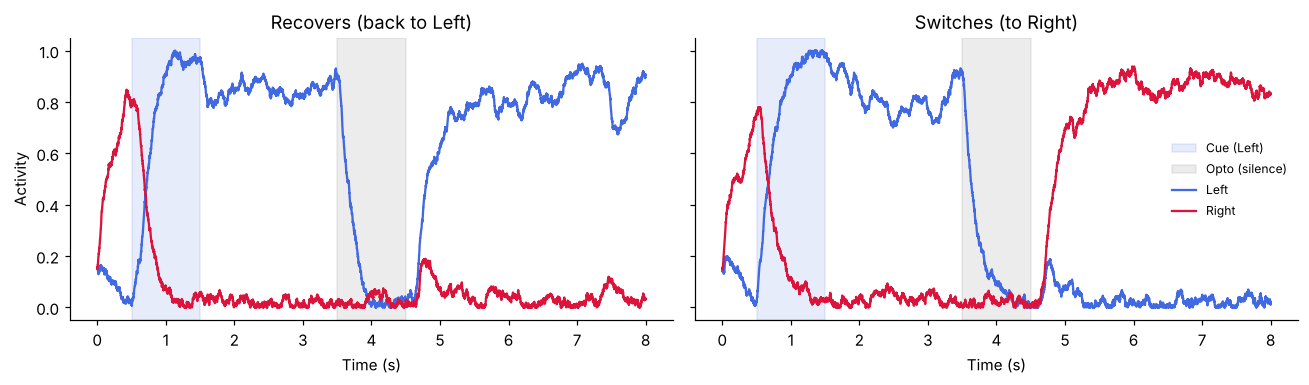

Recovered the Left memory on 50% of 200 trials


In [2]:
task = lambda t: (0.0, 1.2 if 0.5 < t < 1.5 else 0.0, 5.0 if 3.5 < t < 4.5 else 0.0)
t, R = simulate(n_trials=200, T=8, dt=0.001, sigma=0.1, schedule=task, seed=1)
recovered = R[-1, :, 0] > R[-1, :, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, idx, title in [(axes[0], np.where(recovered)[0][0], 'Recovers (back to Left)'),
                       (axes[1], np.where(~recovered)[0][0], 'Switches (to Right)')]:
    ax.axvspan(0.5, 1.5, color=C_L, alpha=0.12, label='Cue (Left)')
    ax.axvspan(3.5, 4.5, color='grey', alpha=0.15, label='Opto (silence)')
    ax.plot(t, R[:, idx, 0], color=C_L, label='Left')
    ax.plot(t, R[:, idx, 1], color=C_R, label='Right')
    ax.set_title(title); ax.set_xlabel('Time (s)')
axes[0].set_ylabel('Activity'); axes[1].legend(loc='center right', fontsize=8, frameon=False)
plt.tight_layout(); plt.show()
print(f"Recovered the Left memory on {recovered.mean():.0%} of {len(recovered)} trials")

Two discrete outcomes and nothing in between: that's the signature of two attractors. (Something to pick apart: with these weights, the opto pulse wipes the memory completely, so recovery is a coin flip. That holds even for a much weaker pulse.)

## Finding the landscape

So far "landscape" has been a metaphor. Can we actually *compute* it for this model? Yes, in three steps:

1. **Find the fixed points**, where $dr/dt = 0$. There are three: Left-wins, Right-wins and a symmetric point in between.
2. **Check their stability** using the eigenvalues of the Jacobian *at each fixed point*. The middle one has one positive eigenvalue: it is a *saddle*, the top of the mountain pass between the two valleys.
3. **Follow the path of least resistance.** Starting from the saddle and nudging it either way, the system rolls down into one of the two valleys. This path is a 1-D curve through the 3-D space of activities, and all the interesting dynamics happen along it (the other directions relax quickly). Measuring position along it with $X = r_L - r_R$ and integrating the speed $dX/dt$ gives a potential, $U(X) = -\int \frac{dX}{dt}\, dX$. That is the landscape.

In [3]:
R_LEFT, R_SADDLE = [0.9, 0.0, 0.75], [0.25, 0.25, 0.27]   # rough initial guesses

def track(h_end, r0, h0=0.0, n=300):
    # Follow a fixed point from h0 to h_end in small steps; stops where it disappears (e.g. at a fold).
    # Success is judged by the residual |dr/dt|, not by fsolve's status flag: with a strict xtol,
    # some numpy/scipy builds report "no further improvement" even when the answer is exact.
    r, out = np.array(r0, float), []
    for h in np.linspace(h0, h_end, n):
        rr = fsolve(drift, r, args=(h,), xtol=1e-12)
        if np.max(abs(drift(rr, h))) > 1e-8 or np.max(abs(rr - r)) > 0.1:   # lost it, or jumped to another fixed point
            break
        r = rr; out.append((h, r.copy()))
    return out

def landscape(h):
    # 1-D landscape along the saddle's unstable manifold, X = r_L - r_R
    h_reached, rs = track(h, R_SADDLE, n=600)[-1]
    w, V = np.linalg.eig(jacobian(rs, h))
    # Sanity checks: track() quietly stops early if the fixed point vanishes, and very close to the
    # tipping point the solver can slide from the pass onto the (nearby) valley floor instead.
    if abs(h_reached - h) > 1e-9 or w.real.max() <= 0:
        raise ValueError(f"landscape({h}): couldn't find the mountain pass (saddle) here. "
                         "Past the tipping point, or too close to it for the solver.")
    v = V[:, np.argmax(w.real)].real                   # direction the saddle is unstable in
    P = []
    for sgn in (+1, -1):
        sol = solve_ivp(lambda t, r: drift(r, h), [0, 40], rs + sgn * 1e-6 * v,
                        max_step=0.005, rtol=1e-10, atol=1e-12)
        P.append(sol.y.T)
    P = np.vstack(P)
    X = P[:, 0] - P[:, 1]
    dX = (drift(P, h)[:, 0] - drift(P, h)[:, 1])
    o = np.argsort(X); X, dX = X[o], dX[o]
    keep = np.r_[True, np.diff(X) > 1e-7]; X, dX = X[keep], dX[keep]
    U = -cumulative_trapezoid(dX, X, initial=0)
    return X, dX, U - U[np.argmin(abs(X - (rs[0] - rs[1])))]  # saddle at U = 0

for name, guess in [('Left wins', R_LEFT), ('saddle', R_SADDLE), ('Right wins', [0.0, 0.9, 0.75])]:
    r = fsolve(drift, guess, xtol=1e-13)
    print(f"{name:>10}: r = {np.round(r, 3)},  eigenvalues = {np.round(np.sort(np.linalg.eigvals(jacobian(r)).real), 1)}")

 Left wins: r = [0.899 0.    0.754],  eigenvalues = [-25.   -8.6  -5. ]
    saddle: r = [0.245 0.245 0.273],  eigenvalues = [-11.3 -11.3  13.5]
Right wins: r = [0.    0.899 0.754],  eigenvalues = [-25.   -8.6  -5. ]


Now let's turn the knob $h$ and push towards Right. The Left valley gets shallower, and the saddle creeps towards it...

Tipping point: h_c = 0.6188, at X_c = 0.528; eigenvalues there: [-11.93 -11.93  -0.  ]


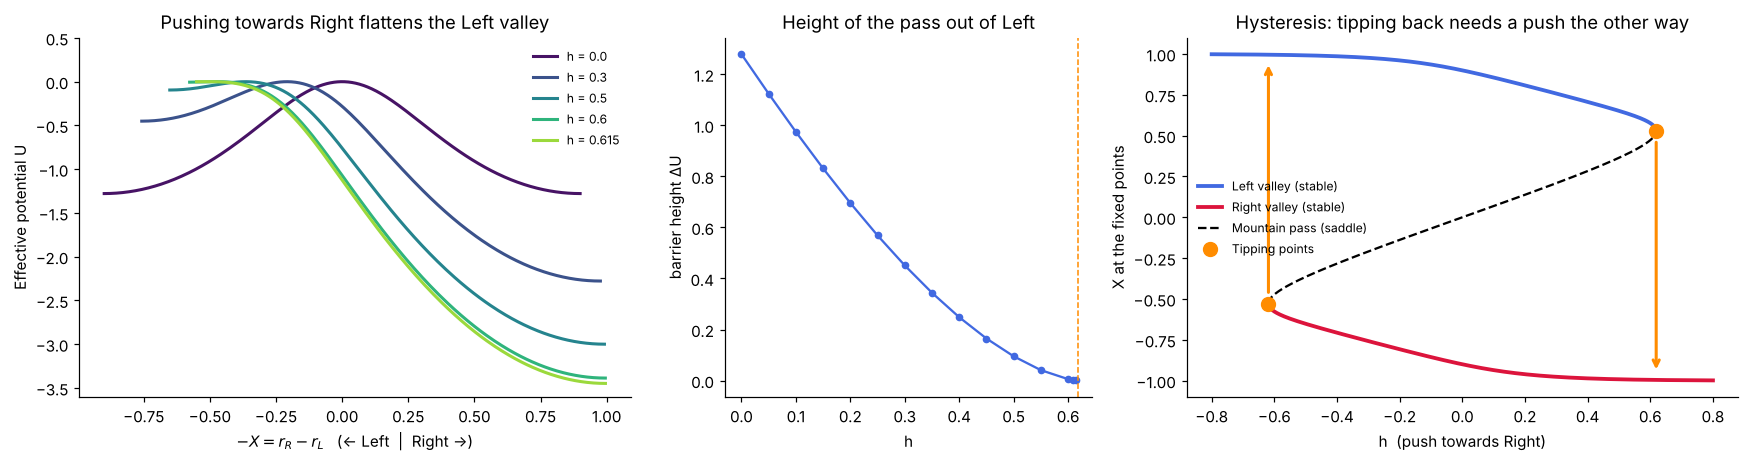

In [4]:
# exact tipping point: a fixed point where the Jacobian has a zero eigenvalue (det J = 0)
near = track(0.7, R_LEFT, n=800)[-1]
sad = track(0.7, R_SADDLE, n=800)[-1]
z = fsolve(lambda z: np.r_[drift(z[:3], z[3]), np.linalg.det(jacobian(z[:3], z[3])) / 1e3],
           np.r_[(near[1] + sad[1]) / 2, near[0]], xtol=1e-14)
r_c, h_c = z[:3], z[3]; X_c = r_c[0] - r_c[1]
print(f"Tipping point: h_c = {h_c:.4f}, at X_c = {X_c:.3f}; eigenvalues there: {np.round(np.sort(np.linalg.eigvals(jacobian(r_c, h_c)).real), 2)}")

fig, (ax1, axz, ax2) = plt.subplots(1, 3, figsize=(16, 4.3), gridspec_kw={'width_ratios': [1.2, 0.8, 1.2]})
hs_show = [0.0, 0.3, 0.5, 0.6, 0.615]
cols = plt.cm.viridis(np.linspace(0.05, 0.85, len(hs_show)))
for h, c in zip(hs_show, cols):
    X, dX, U = landscape(h)
    ax1.plot(-X, U, color=c, lw=2, label=f'h = {h}')   # plot -X so the Left valley sits on the left
# barrier height: how high is the pass above the Left valley floor?
h_grid = np.r_[np.linspace(0, 0.6, 13), h_c - 0.01, h_c - 0.005]   # stay a safe distance from h_c
def barrier_height(h):
    X, _, U = landscape(h)
    return -U[X > X[np.argmax(U)]].min()   # depth of the Left valley below the pass (U = 0 at the pass)
barrier = [barrier_height(h) for h in h_grid]
axz.plot(h_grid, barrier, 'o-', color=C_L, ms=4)
axz.axvline(h_c, color=C_FOLD, ls='--', lw=1)
axz.set_xlabel('h'); axz.set_ylabel('barrier height ΔU'); axz.set_title('Height of the pass out of Left')
ax1.set_xlabel(r'$-X = r_R - r_L$   (← Left  |  Right →)'); ax1.set_ylabel('Effective potential U')
ax1.set_title('Pushing towards Right flattens the Left valley'); ax1.legend(frameon=False, fontsize=8)
ax1.set_ylim(-3.6, 0.5)

# bifurcation diagram: fixed points X* as a function of h (use L/R symmetry for negative h)
left = track(0.7, R_LEFT, h0=-0.8, n=1500)
saddle = track(h_c, R_SADDLE, n=600)
hL = np.array([p[0] for p in left]); XL = np.array([p[1][0] - p[1][1] for p in left])
hS = np.array([p[0] for p in saddle]); XS = np.array([p[1][0] - p[1][1] for p in saddle])
ax2.plot(hL, XL, color=C_L, lw=2.5, label='Left valley (stable)')
ax2.plot(-hL, -XL, color=C_R, lw=2.5, label='Right valley (stable)')
ax2.plot(np.r_[-hS[::-1], hS], np.r_[-XS[::-1], XS], 'k--', lw=1.5, label='Mountain pass (saddle)')
ax2.plot([h_c, -h_c], [X_c, -X_c], 'o', color=C_FOLD, ms=9, label='Tipping points')
ax2.annotate('', xy=(h_c, -0.95), xytext=(h_c, X_c - 0.05), arrowprops=dict(arrowstyle='->', color=C_FOLD, lw=2))
ax2.annotate('', xy=(-h_c, 0.95), xytext=(-h_c, -X_c + 0.05), arrowprops=dict(arrowstyle='->', color=C_FOLD, lw=2))
ax2.set_xlabel('h  (push towards Right)'); ax2.set_ylabel('X at the fixed points')
ax2.set_title('Hysteresis: tipping back needs a push the other way'); ax2.legend(frameon=False, fontsize=8, loc='center left')
plt.tight_layout(); plt.show()

At $h_c \approx 0.62$ the Left valley and the mountain pass meet and annihilate each other. This is a **saddle-node (fold) bifurcation**. After it, there is nowhere left to stay: the system has to roll into the Right valley.

The right-hand plot is the part that matters for climate. Undoing the push (bringing $h$ back to 0) does **not** bring you back to Left, because you are now sitting in the Right valley, which is perfectly stable at $h=0$. To return you'd need to push all the way to $-h_c$. That is **hysteresis**, and it is exactly what "irreversible" means for the AMOC.

The middle plot shows the height of the pass, which falls steadily as we push. Keep an eye on it: a lower pass means a random kick is more likely to carry you over, long before the valley disappears completely.

## Zooming in on the edge: Ditlevsen's equation

Here is the bridge. Ditlevsen & Ditlevsen model the AMOC with

$$dX_t = -\big(A(X_t - m)^2 + \lambda_t\big)\,dt + \sigma\, dB_t .$$

While $\lambda < 0$ this has two fixed points, $X = m \pm \sqrt{-\lambda/A}$. The upper one is stable (the valley) and the lower one is unstable (the pass). As $\lambda \to 0$ they merge at $X=m$, and for $\lambda > 0$ there is no fixed point at all. In other words: **it is a fold, and nothing else.** It describes *one* valley and the edge it falls off, not the whole double-well.

Why should a fold in the ocean look like a fold in the brain? Because near *any* fold, Taylor-expanding the dynamics along the one slow direction gives a parabola. The constant term is set by the control parameter and the linear term vanishes at the fold. The fast directions (eigenvalues of about $-12\,\text{s}^{-1}$ at our fold) just get dragged along. So near $h_c$ our 3-population model *must* reduce to Ditlevsen's 1-D equation, with

$$m = X_c,\qquad \lambda(h) \approx \kappa\,(h - h_c).$$

We can read $A$ and $\kappa$ straight off the model. The distance between the valley and the pass is $2\sqrt{-\lambda/A}$, and the valley's slowest eigenvalue is $-2\sqrt{-A\lambda}$, so dividing one by the other gives $A$.

Near the edge the neural model is Ditlevsen's equation with A = 30.5, m = 0.528, lambda = 4.18 (h - 0.619)


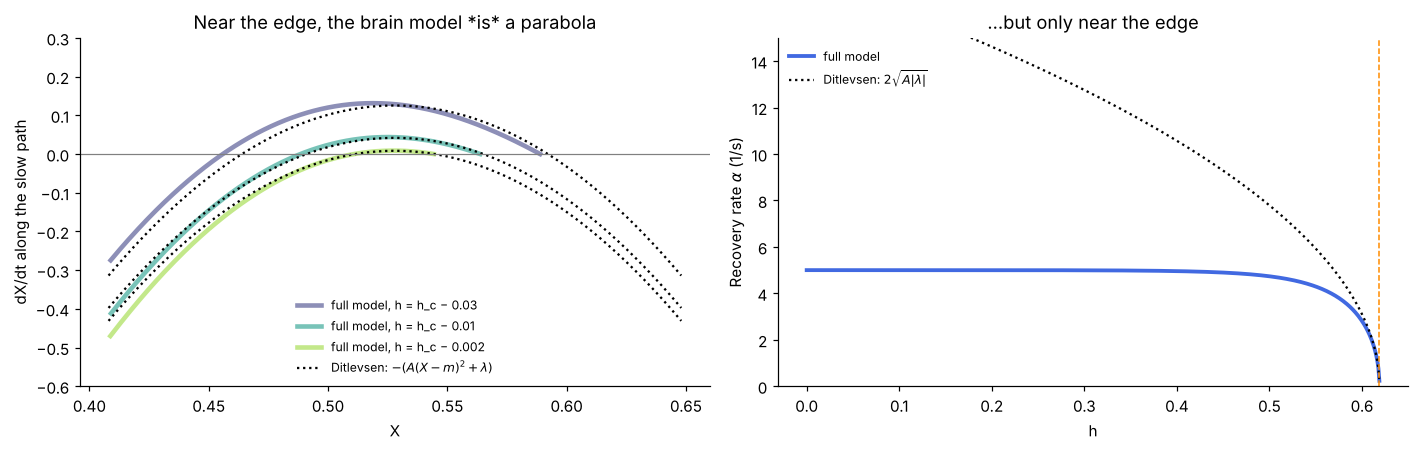

In [5]:
hs = np.linspace(h_c - 0.004, h_c - 2e-5, 20)
A_est, lam_est = [], []
for h in hs:
    rn = fsolve(drift, track(h, R_LEFT)[-1][1], args=(h,), xtol=1e-14)    # valley
    rs = fsolve(drift, track(h, R_SADDLE)[-1][1], args=(h,), xtol=1e-14)  # pass
    gap = (rn[0] - rn[1]) - (rs[0] - rs[1])                                # = 2 sqrt(-lambda/A)
    slow = np.max(np.linalg.eigvals(jacobian(rn, h)).real)                 # = -2 sqrt(-A lambda)
    A_est.append(-slow / gap); lam_est.append(slow * gap / 4)
A_nf = np.mean(A_est); kappa = np.polyfit(hs, lam_est, 1)[0]
print(f"Near the edge the neural model is Ditlevsen's equation with A = {A_nf:.1f}, m = {X_c:.3f}, lambda = {kappa:.2f} (h - {h_c:.3f})")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
for dh, c in zip([0.03, 0.01, 0.002], plt.cm.viridis([0.2, 0.55, 0.85])):
    h = h_c - dh
    X, dX, _ = landscape(h)
    win = (X > X_c - 0.12) & (X < X_c + 0.12)
    ax1.plot(X[win], dX[win], color=c, lw=3, alpha=0.6, label=f'full model, h = h_c − {dh}')
    Xg = np.linspace(X_c - 0.12, X_c + 0.12, 200)
    ax1.plot(Xg, -(A_nf * (Xg - X_c) ** 2 + kappa * (h - h_c)), 'k:', lw=1.5)
ax1.axhline(0, color='grey', lw=0.8)
ax1.plot([], [], 'k:', label=r'Ditlevsen: $-(A(X-m)^2+\lambda)$')
ax1.set_xlabel('X'); ax1.set_ylabel('dX/dt along the slow path'); ax1.set_ylim(-0.6, 0.3)
ax1.set_title('Near the edge, the brain model *is* a parabola'); ax1.legend(frameon=False, fontsize=8)

# how fast does the valley pull you back?  alpha = -slowest eigenvalue
valley = track(h_c - 1e-4, R_LEFT, n=600)                  # Left valley from h = 0 up to the edge
assert len(valley) == 600, f"lost the Left valley at h = {valley[-1][0]:.3f}"
hh = np.array([p[0] for p in valley]); rr = [p[1] for p in valley]
alpha_true = [-np.max(np.linalg.eigvals(jacobian(r, h)).real) for h, r in zip(hh, rr)]
alpha_nf = 2 * np.sqrt(A_nf * kappa * (h_c - hh))
ax2.plot(hh, alpha_true, color=C_L, lw=2.5, label='full model')
ax2.plot(hh, alpha_nf, 'k:', lw=1.5, label=r'Ditlevsen: $2\sqrt{A|\lambda|}$')
ax2.axvline(h_c, color=C_FOLD, ls='--', lw=1)
ax2.set_xlabel('h'); ax2.set_ylabel(r'Recovery rate $\alpha$ (1/s)'); ax2.set_ylim(0, 15)
ax2.set_title('...but only near the edge'); ax2.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

Left: close to the edge, the full 3-population model and the one-line parabola overlap. Right: further away they don't. The recovery rate $\alpha$ (how hard the valley pulls you back after a kick) sits at $\approx 1/\tau = 5\,\text{s}^{-1}$ almost all the way, and only collapses in the last stretch before $h_c$. That's because the suppressed Right population is pinned near zero, where its sigmoid is flat. Put this next to the barrier plot: **the valley gets shallower without getting narrower at the bottom.** Remember this; it comes back to bite us.

## Feeling the edge: critical slowing down

Why does $\alpha$ matter? Linearise Ditlevsen's equation around the valley floor $\mu = m + \sqrt{-\lambda/A}$ and you get the simplest noisy system there is, an Ornstein–Uhlenbeck process:

$$dX = -\alpha (X - \mu)\,dt + \sigma\, dB, \qquad \alpha = 2\sqrt{-A\lambda}.$$

Its fluctuations have variance $\sigma^2 / 2\alpha$ and autocorrelation $e^{-\alpha\,\Delta t}$ at lag $\Delta t$. As $\lambda \to 0$, $\alpha \to 0$: **the wobbles get bigger and slower**. A shallow valley can't pull you back quickly. That's *critical slowing down*, and it's the early-warning signal Ditlevsen & Ditlevsen look for in the ocean.

Let's ramp $h$ slowly in the brain model, using Ditlevsen's schedule: constant until $t_0$, then increasing linearly so that it crosses $h_c$ at $t = 40$ s.

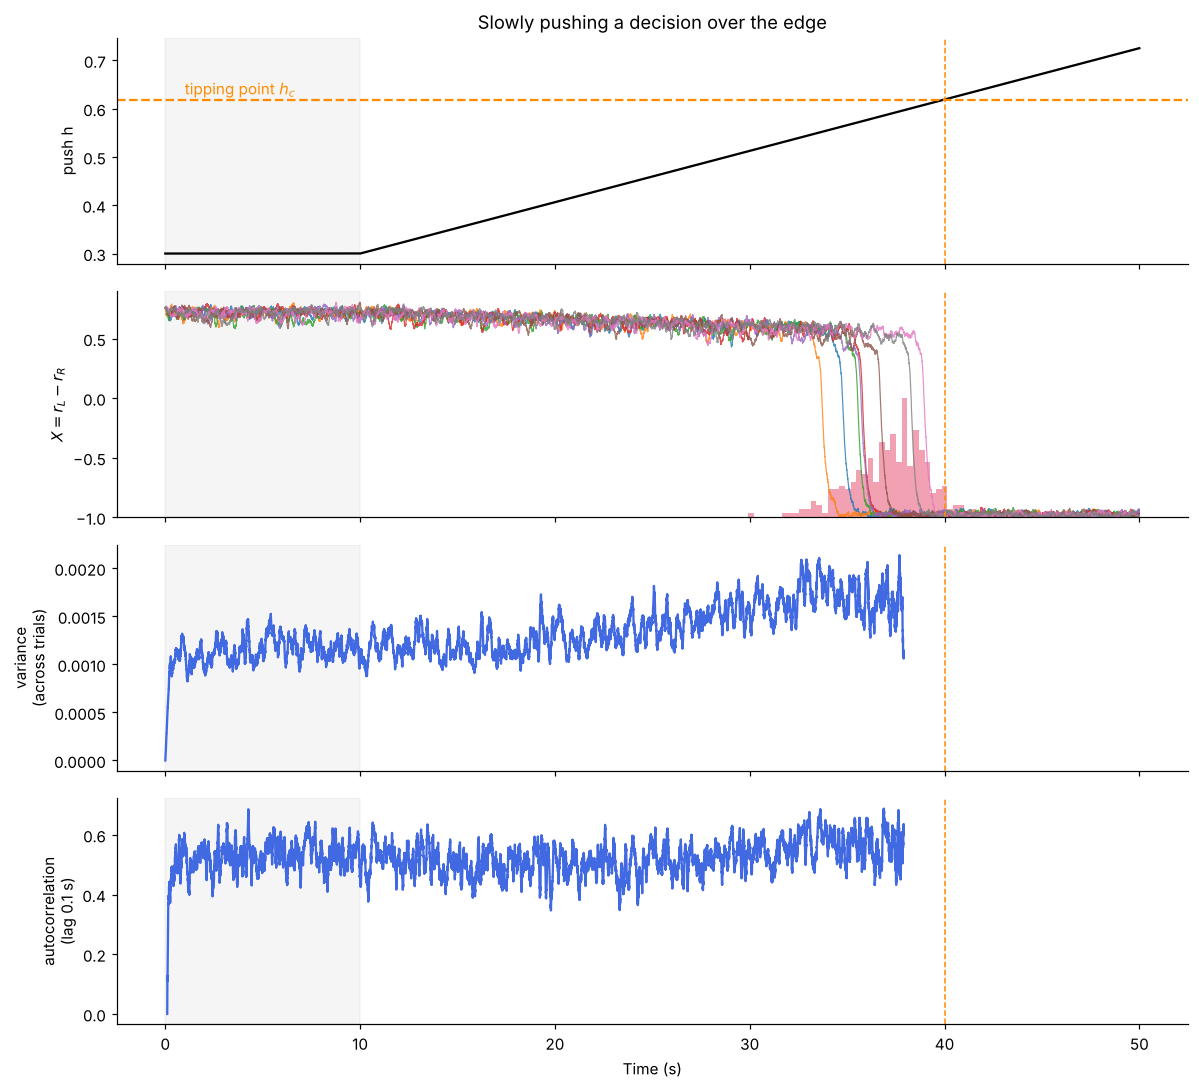

Deterministic tipping at t = 40 s; noisy trials actually switch at 37.4 s (median; 90% between 34.0 and 40.0 s)


In [6]:
h0, t0, t_cross = 0.3, 10.0, 40.0
rate = (h_c - h0) / (t_cross - t0)
h_of_t = lambda t: h0 + rate * max(0.0, t - t0)
ramp = lambda t: (h_of_t(t), 0.0, 0.0)
r_start = track(h0, R_LEFT)[-1][1]
t, R = simulate(n_trials=300, T=50, dt=0.002, sigma=0.05, schedule=ramp, r0=r_start, seed=2)
X = R[:, :, 0] - R[:, :, 1]
switch_t = np.array([t[np.argmax(x < 0)] if (x < 0).any() else np.nan for x in X.T])

# across-trial statistics, using only trials that haven't switched yet
lag = int(0.1 / 0.002)
still_left = t[:, None] < switch_t[None, :] - 1.0
Xm = np.where(still_left, X, np.nan)
var = np.nanvar(Xm, axis=1)
dev = Xm - np.nanmean(Xm, axis=1, keepdims=True)
ac = np.nanmean(dev[lag:] * dev[:-lag], axis=1) / np.sqrt(var[lag:] * var[:-lag])
enough = np.sum(still_left, axis=1) >= 50

fig, axes = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
axes[0].plot(t, [h_of_t(s) for s in t], color='k'); axes[0].axhline(h_c, color=C_FOLD, ls='--')
axes[0].set_ylabel('push h'); axes[0].text(1, h_c + 0.01, 'tipping point $h_c$', color=C_FOLD)
for i in range(8):
    axes[1].plot(t, X[:, i], lw=0.8, alpha=0.8)
axes[1].set_ylabel(r'$X = r_L - r_R$')
axes[2].plot(t[enough], var[enough], color=C_L); axes[2].set_ylabel('variance\n(across trials)')
axes[3].plot(t[lag:][enough[lag:]], ac[enough[lag:]], color=C_L); axes[3].set_ylabel('autocorrelation\n(lag 0.1 s)')
for ax in axes:
    ax.axvline(t_cross, color=C_FOLD, ls='--', lw=1); ax.axvspan(0, t0, color='grey', alpha=0.08)
axes[1].hist(switch_t, bins=40, bottom=-1, weights=np.full(len(switch_t), 2 / 60), color=C_R, alpha=0.4)
axes[3].set_xlabel('Time (s)'); axes[0].set_title('Slowly pushing a decision over the edge')
plt.tight_layout(); plt.show()
print(f"Deterministic tipping at t = {t_cross:.0f} s; noisy trials actually switch at "
      f"{np.nanmedian(switch_t):.1f} s (median; 90% between {np.nanpercentile(switch_t, 5):.1f} and {np.nanpercentile(switch_t, 95):.1f} s)")

Three things to notice:

* **Variance creeps up before the switch.** The warning signal is there...
* **...but it's weak.** Variance grows by only about 50%, and the autocorrelation barely moves. This matches the recovery-rate plot above: the valley only gets truly shallow in the last stretch, and by then most trials have already gone over.
* **Noise tips you early.** Most trials switch *before* $t = 40$ s, because when the valley is shallow a random kick is enough to get over the remaining hump. Ditlevsen's estimate is the time at which $\lambda = 0$. For a noisy system that is an *upper bound* on when tipping happens.

## Predicting a change of mind (Ditlevsen's method)

Now the fun part: can we predict *when* the system will tip, using only the data recorded *before* it does? This is what Ditlevsen & Ditlevsen did with 150 years of ocean temperatures. Their recipe has two steps:

1. **Baseline (before $t_0$).** $\lambda$ is constant, so the data are an Ornstein–Uhlenbeck process. Fit it to get the valley floor $\mu_0$, the recovery rate $\alpha_0$ and the noise $\sigma$.
2. **Ramp (after $t_0$).** $\mu_0$ and $\alpha_0$ already tie $m$ and $\lambda_0$ to $A$ ($m = \mu_0 - \alpha_0/2A$ and $\lambda_0 = -\alpha_0^2/4A$). So only $A$ and the ramp time $\tau_r$ remain. Find them by maximum likelihood on the rest of the record. The predicted tipping time is $t_c = t_0 + \tau_r$.

(They also estimate $t_0$; here I give it to the estimator. And I use the simplest likelihood, an Euler discretisation of the equation, rather than their more careful approximation.)

First, a sanity check on data that really *are* Ditlevsen's equation, stopping the record at $t = 33$ s, well before the true $t_c = 40$ s:

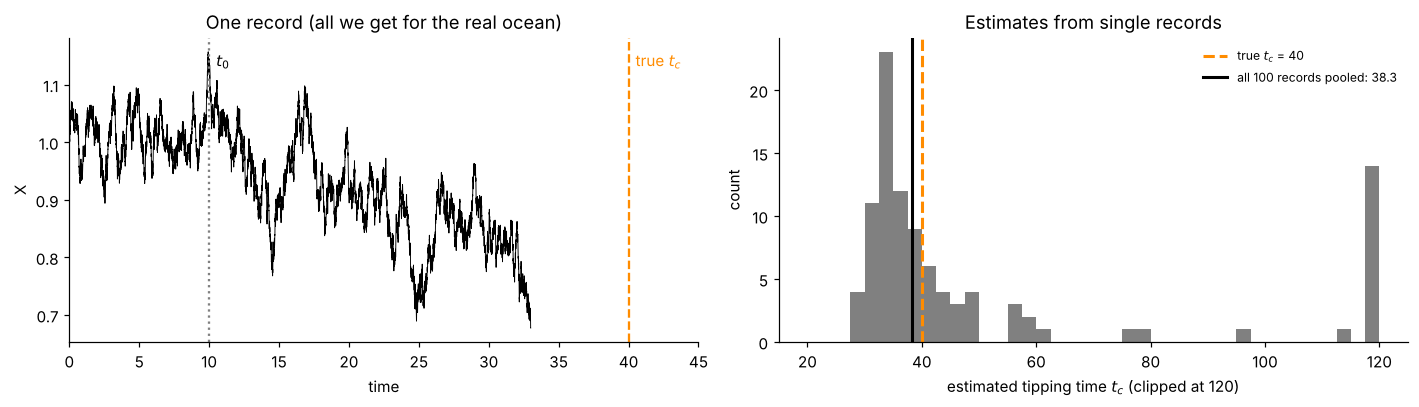

Single-record estimates: median 37.5, middle 50% between 33.3 and 49.5


In [7]:
def fit_ditlevsen(ts, x, t0, t_now, dt):
    # x: (time,) for one record or (time, n) for several records sharing the same parameters
    keep = ts < t_now; ts, x = ts[keep], x[keep]
    base = ts < t0
    xb = x[base]
    b, a = np.polyfit(xb[:-1].ravel(), xb[1:].ravel(), 1)            # step 1: AR(1) = OU process
    alpha0, mu0 = -np.log(b) / dt, a / (1 - b)
    s2 = 2 * alpha0 * np.var(xb[1:] - (a + b * xb[:-1])) / (1 - b**2)
    xr, tr_ = x[~base], ts[~base]
    def nll(p):                                                       # step 2: A and tau_r
        A, tau_r = np.exp(p)
        m, lam0 = mu0 - alpha0 / (2 * A), -alpha0**2 / (4 * A)
        lam = (lam0 * (1 - (tr_[:-1] - t0) / tau_r)).reshape((-1,) + (1,) * (xr.ndim - 1))
        pred = xr[:-1] - (A * (xr[:-1] - m)**2 + lam) * dt
        return 0.5 * np.sum((xr[1:] - pred)**2) / (s2 * dt)
    best = min((minimize(nll, np.log([A0, T0]), method='Nelder-Mead')
                for A0 in (1, 3, 10, 30) for T0 in (10, 30, 100)), key=lambda r: r.fun)
    A, tau_r = np.exp(best.x)
    return dict(t_c=t0 + tau_r, A=A, tau_r=tau_r, alpha0=alpha0, mu0=mu0, sigma=np.sqrt(s2))

# simulate Ditlevsen's equation itself: 100 independent "Earths"
rng = np.random.default_rng(0)
A_true, m_true, lam0_true, sig_true, t0, tau_true = 2.0, 0.5, -0.5, 0.1, 10.0, 30.0
dt_sim, k = 0.002, 10
ts = np.arange(0, 33, dt_sim)
x = np.full(100, m_true + np.sqrt(-lam0_true / A_true)); XD = np.empty((len(ts), 100))
for i, s in enumerate(ts):
    XD[i] = x
    lam = lam0_true * (1 - max(0.0, s - t0) / tau_true)
    x = x - (A_true * (x - m_true)**2 + lam) * dt_sim + sig_true * np.sqrt(dt_sim) * rng.standard_normal(100)

single = np.array([fit_ditlevsen(ts[::k], XD[::k, i], t0, 33, k * dt_sim)['t_c'] for i in range(100)])
pooled = fit_ditlevsen(ts[::k], XD[::k], t0, 33, k * dt_sim)['t_c']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
ax1.plot(ts, XD[:, 0], color='k', lw=0.6); ax1.axvline(t0, color='grey', ls=':'); ax1.axvline(40, color=C_FOLD, ls='--')
ax1.set_xlim(0, 45); ax1.set_xlabel('time'); ax1.set_ylabel('X'); ax1.set_title('One record (all we get for the real ocean)')
ax1.text(t0 + 0.5, ax1.get_ylim()[1] * 0.98, '$t_0$', va='top'); ax1.text(40.5, ax1.get_ylim()[1] * 0.98, 'true $t_c$', color=C_FOLD, va='top')
ax2.hist(np.clip(single, 20, 120), bins=np.arange(20, 122, 2.5), color='grey')
ax2.axvline(40, color=C_FOLD, ls='--', lw=2, label='true $t_c$ = 40')
ax2.axvline(pooled, color='k', lw=2, label=f'all 100 records pooled: {pooled:.1f}')
ax2.set_xlabel('estimated tipping time $t_c$ (clipped at 120)'); ax2.set_ylabel('count')
ax2.set_title('Estimates from single records'); ax2.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
print(f"Single-record estimates: median {np.median(single):.1f}, middle 50% between {np.percentile(single, 25):.1f} and {np.percentile(single, 75):.1f}")

The method works: pool many records and it lands close to the truth. But from a *single* record the estimate scatters widely, with a long tail towards "much later". The ocean gives us exactly one record. Neuroscience gives us hundreds of trials.

Now the real test: the brain model, where the equation is only an *approximation* that holds near the edge.

In [8]:
t, R = simulate(n_trials=50, T=33, dt=0.002, sigma=0.05, schedule=ramp, r0=r_start, seed=3)
Xn = R[:, :, 0] - R[:, :, 1]
fit_n = fit_ditlevsen(t[::10], Xn[::10], t0, 33, 0.02)
print(f"Brain model, 50 trials pooled: predicted t_c = {fit_n['t_c']:.0f} s   (true deterministic tipping at {t_cross:.0f} s)")
print(f"  baseline recovery rate alpha0 = {fit_n['alpha0']:.1f}/s, true slowest eigenvalue at h0: "
      f"{-np.max(np.linalg.eigvals(jacobian(r_start, h0)).real):.1f}/s")

Brain model, 50 trials pooled: predicted t_c = 65 s   (true deterministic tipping at 40 s)
  baseline recovery rate alpha0 = 2.9/s, true slowest eigenvalue at h0: 5.0/s


Even with 50 pooled trials, the prediction comes out much too late. This isn't bad luck. There are two culprits:

1. **The shape is wrong.** The estimator *assumes* the valley is a parabola for the whole record, so a recovery rate that barely changes reads as "the edge is far away". In our model the landscape keeps its shape until very close to $h_c$ and then gives way suddenly.
2. **The measurement is not one-dimensional.** $X = r_L - r_R$ mixes the slow direction with fast ones (and the Right population bumps against zero), so even the baseline recovery rate comes out wrong (about 3/s instead of 5/s).

The lesson carries straight over to the ocean: **the method's prediction is only as good as its assumption that the whole record already sits on the parabolic part of the landscape.** If the real system is more like our neurons (stiff, then sudden), the warning signals would come late and the extrapolated date would be *optimistic*.

---

# When climate change will be irreversible

*(draft: explaining how Ditlevsen & Ditlevsen (2023) model the data)*

The **Atlantic Meridional Overturning Circulation (AMOC)** carries warm, salty surface water north. In the North Atlantic that water cools, sinks and returns south at depth. The classic box model (Stommel, 1961) already had two stable states, "on" and "off". The feedback is salt: a strong current imports salt, which keeps northern water dense enough to sink, which keeps the current strong. Melting ice and extra rain add fresh water, weakening that feedback. Push far enough and the "on" valley disappears, which is a fold like the one in our neurons.

**What they measure.** Direct AMOC measurements only began in 2004 (the RAPID array at 26°N), which is far too short. So they use a *fingerprint*, following Caesar et al. (2018): sea-surface temperature in the **subpolar gyre** south of Greenland, minus the global mean SST. When the AMOC weakens, less heat arrives there and that patch cools relative to the rest of the planet (the "cold blob"). Subtracting the global mean removes global warming, which would otherwise dominate. The data are monthly HadISST anomalies from 1870 onwards.

**The model.** Exactly the equation we derived for the brain, with a forcing that is constant until a year $t_0$ and then ramps linearly:

$$dX_t = -\big(A(X_t - m)^2 + \lambda_t\big)\,dt + \sigma\, dB_t,\qquad \lambda_t = \lambda_0\Big(1 - \Theta(t-t_0)\,\frac{t - t_0}{\tau_r}\Big).$$

The linear ramp is the same logic as $\lambda \approx \kappa (h - h_c)$. Near a fold, $\lambda$ is linear in the forcing (greenhouse gases, freshwater), and the forcing has grown roughly linearly in time.

**The fit.** The same two steps as above. The early record (before $t_0$) is treated as a stationary Ornstein–Uhlenbeck process, giving $\mu_0$, $\alpha_0$ and $\sigma$. The rest of the record then pins down $A$, $\tau_r$ and $t_0$ by maximum likelihood, and $t_c = t_0 + \tau_r$ is the year $\lambda$ hits zero. They also check the warning signs directly: the variance and lag-1 autocorrelation of the fingerprint have both increased significantly over the 20th century.

**The headline.** Forcing starts ramping in the 1920s, and the tipping point arrives around the middle of this century, with a 95% interval of roughly 2025–2095 under current emissions.

**What I'd pick apart** (much of it is visible in the toy models above):

* *The proxy.* Is subpolar-gyre temperature really the AMOC? Other things (aerosols, wind-driven changes) can also cool that patch.
* *The shape.* The method assumes the whole 150-year record already sits on the parabolic part of the landscape. Our brain model shows how the date can come out wrong when that fails.
* *One Earth.* A single record gives wide uncertainty, as the histogram above shows. Later papers have argued the uncertainty is larger still.
* *Noise tips early.* $t_c$ is when the valley disappears. With noise the jump can come before that.
* *Hysteresis.* If it does tip, our bifurcation diagram says that cutting emissions back to today's level won't switch it back on.

| | Decision (brain) | AMOC (ocean) |
|---|---|---|
| State $X$ | $r_L - r_R$ | subpolar-gyre SST − global SST |
| Valley you start in | "Left" | AMOC "on" |
| Push $\lambda$ | evidence / perturbation $h$ towards Right | freshwater + warming |
| Fold | Left valley vanishes at $h_c$ | "on" state vanishes |
| Afterwards | commit to Right | collapsed AMOC, hard to reverse |
| Data | hundreds of trials | one record, 150 years |

### References
* Inagaki, Fontolan, Romani & Svoboda (2019). *Discrete attractor dynamics underlies persistent activity in the frontal cortex.* Nature.
* Ditlevsen & Ditlevsen (2023). *Warning of a forthcoming collapse of the Atlantic meridional overturning circulation.* Nature Communications.
* Caesar et al. (2018). *Observed fingerprint of a weakening Atlantic Ocean overturning circulation.* Nature.
* Stommel (1961). *Thermohaline convection with two stable regimes of flow.* Tellus.